In [68]:
import json 
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from pathlib import Path
from datetime import datetime
from sklearn.calibration import calibration_curve

In [69]:
dataset = "sics155_c19_vmae"
split = 1
epoch = 3000
source = "validation"   # calibration should be judged on held-out data
num_bins = 100

log_dir = Path("./prob_logs") / dataset / f"split_{split}" / source
candidates = sorted(log_dir.glob(f"epoch_{epoch}_*_probabilities.json"))
input_path = next((p for p in candidates if "validation" in p.name), candidates[0])
probabilites_per_video = json.load(open(input_path))
print(f"Loaded {input_path} (last changed {datetime.fromtimestamp(input_path.stat().st_mtime)})")

action_mapping = probabilites_per_video["metadata"]["action_mapping"]  # name -> id
class_names = [name for name, _ in sorted(action_mapping.items(), key=lambda kv: kv[1])]
num_classes = len(class_names)


Loaded prob_logs/sics155_c19_vmae/split_1/validation/epoch_3000_validation_probabilities.json (last changed 2026-07-10 13:51:08.247923)


In [70]:
def load_gt(vid, mapping, gt_dir=Path("./data") / dataset / "groundTruth"):
    labels = (gt_dir / f"{vid}.txt").read_text().splitlines()
    return np.asarray([mapping.get(name, 0) for name in labels], dtype=int)

y_true_chunks, y_prob_chunks = [], []
for vid, vdat in probabilites_per_video["video_probabilities"].items():
    gt = load_gt(vid, action_mapping)
    probs = np.asarray(vdat["logits"]).T           # (T, C), already per-class probabilities
    T = min(len(gt), probs.shape[0])
    y_true_chunks.append(gt[:T])
    y_prob_chunks.append(probs[:T])

y_true = np.concatenate(y_true_chunks)             # (N,) int class ids
y_prob = np.concatenate(y_prob_chunks, axis=0)     # (N, C) per-class probabilities
print(y_true.shape, y_prob.shape)


(177839,) (177839, 19)


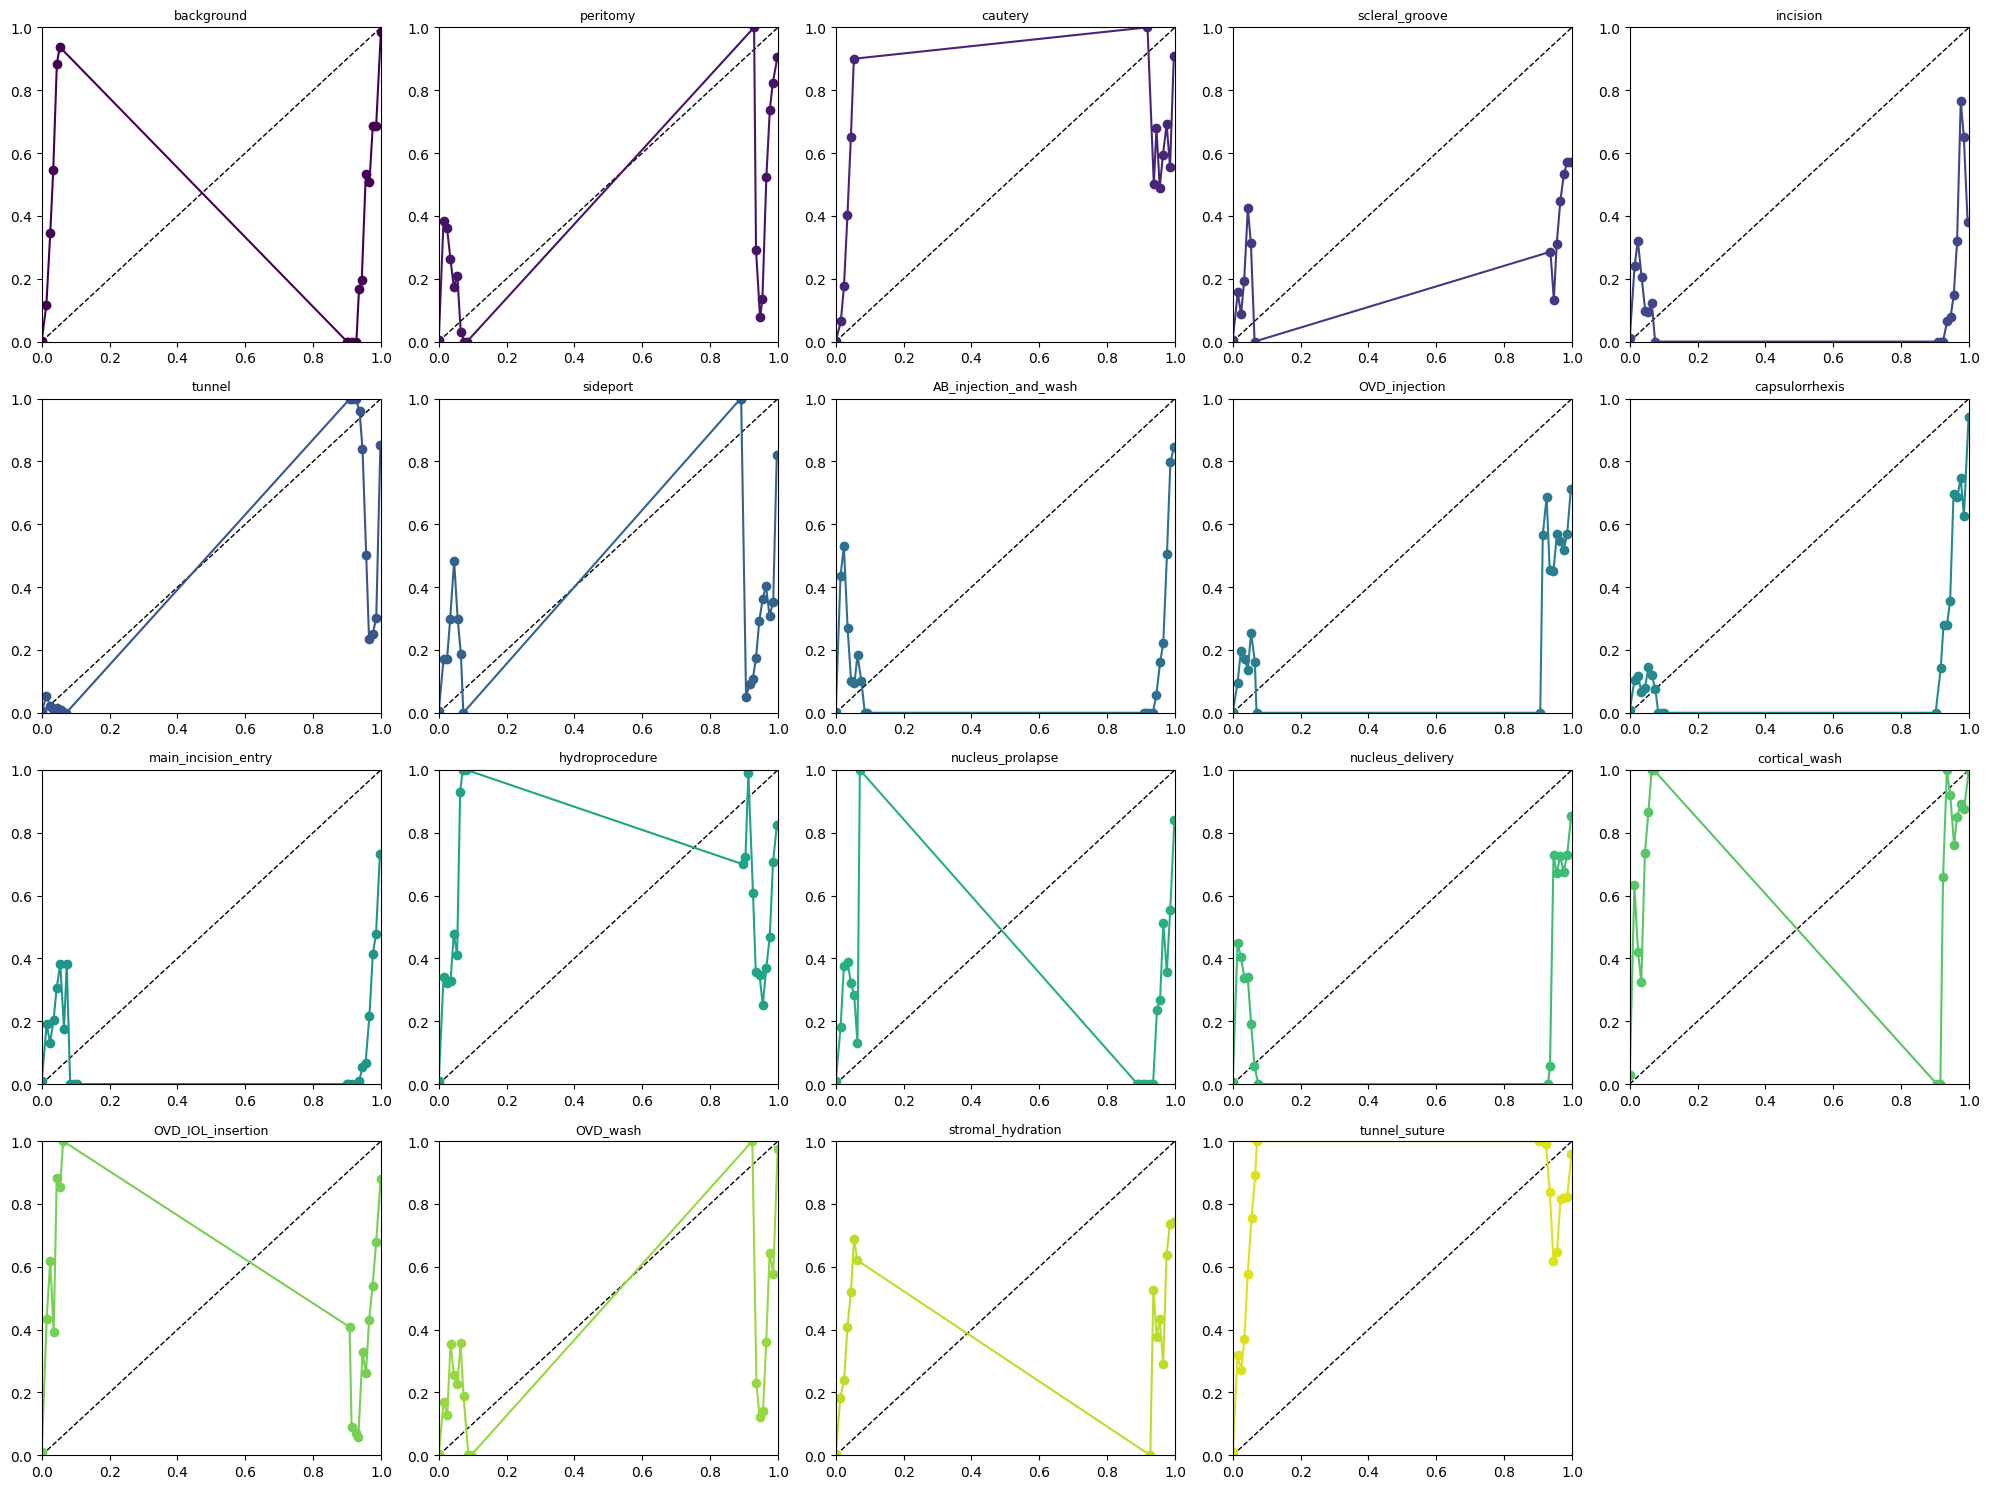

In [77]:
def plot_calibration_grid(y_true, y_prob, class_names, n_bins=num_bins, title=None):
    num_classes = len(class_names)
    fig = plt.figure(figsize=(20, 15))
    gs = GridSpec(4, 5)
    colors = plt.get_cmap("viridis")
    grid_pos = [(i // 5, i % 5) for i in range(20)]

    for c in range(num_classes):
        ax = fig.add_subplot(gs[grid_pos[c]])
        frac_pos, mean_pred = calibration_curve(
            (y_true == c).astype(int), y_prob[:, c], n_bins=n_bins, strategy="uniform"
        )
        ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="perfect")
        ax.plot(mean_pred, frac_pos, marker="o", color=colors(c / num_classes))
        ax.set_title(class_names[c], fontsize=9)
        ax.set_xlim(0, 1); ax.set_ylim(0, 1)

    if title:
        fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()
    return fig

plot = plot_calibration_grid(y_true, y_prob, class_names)


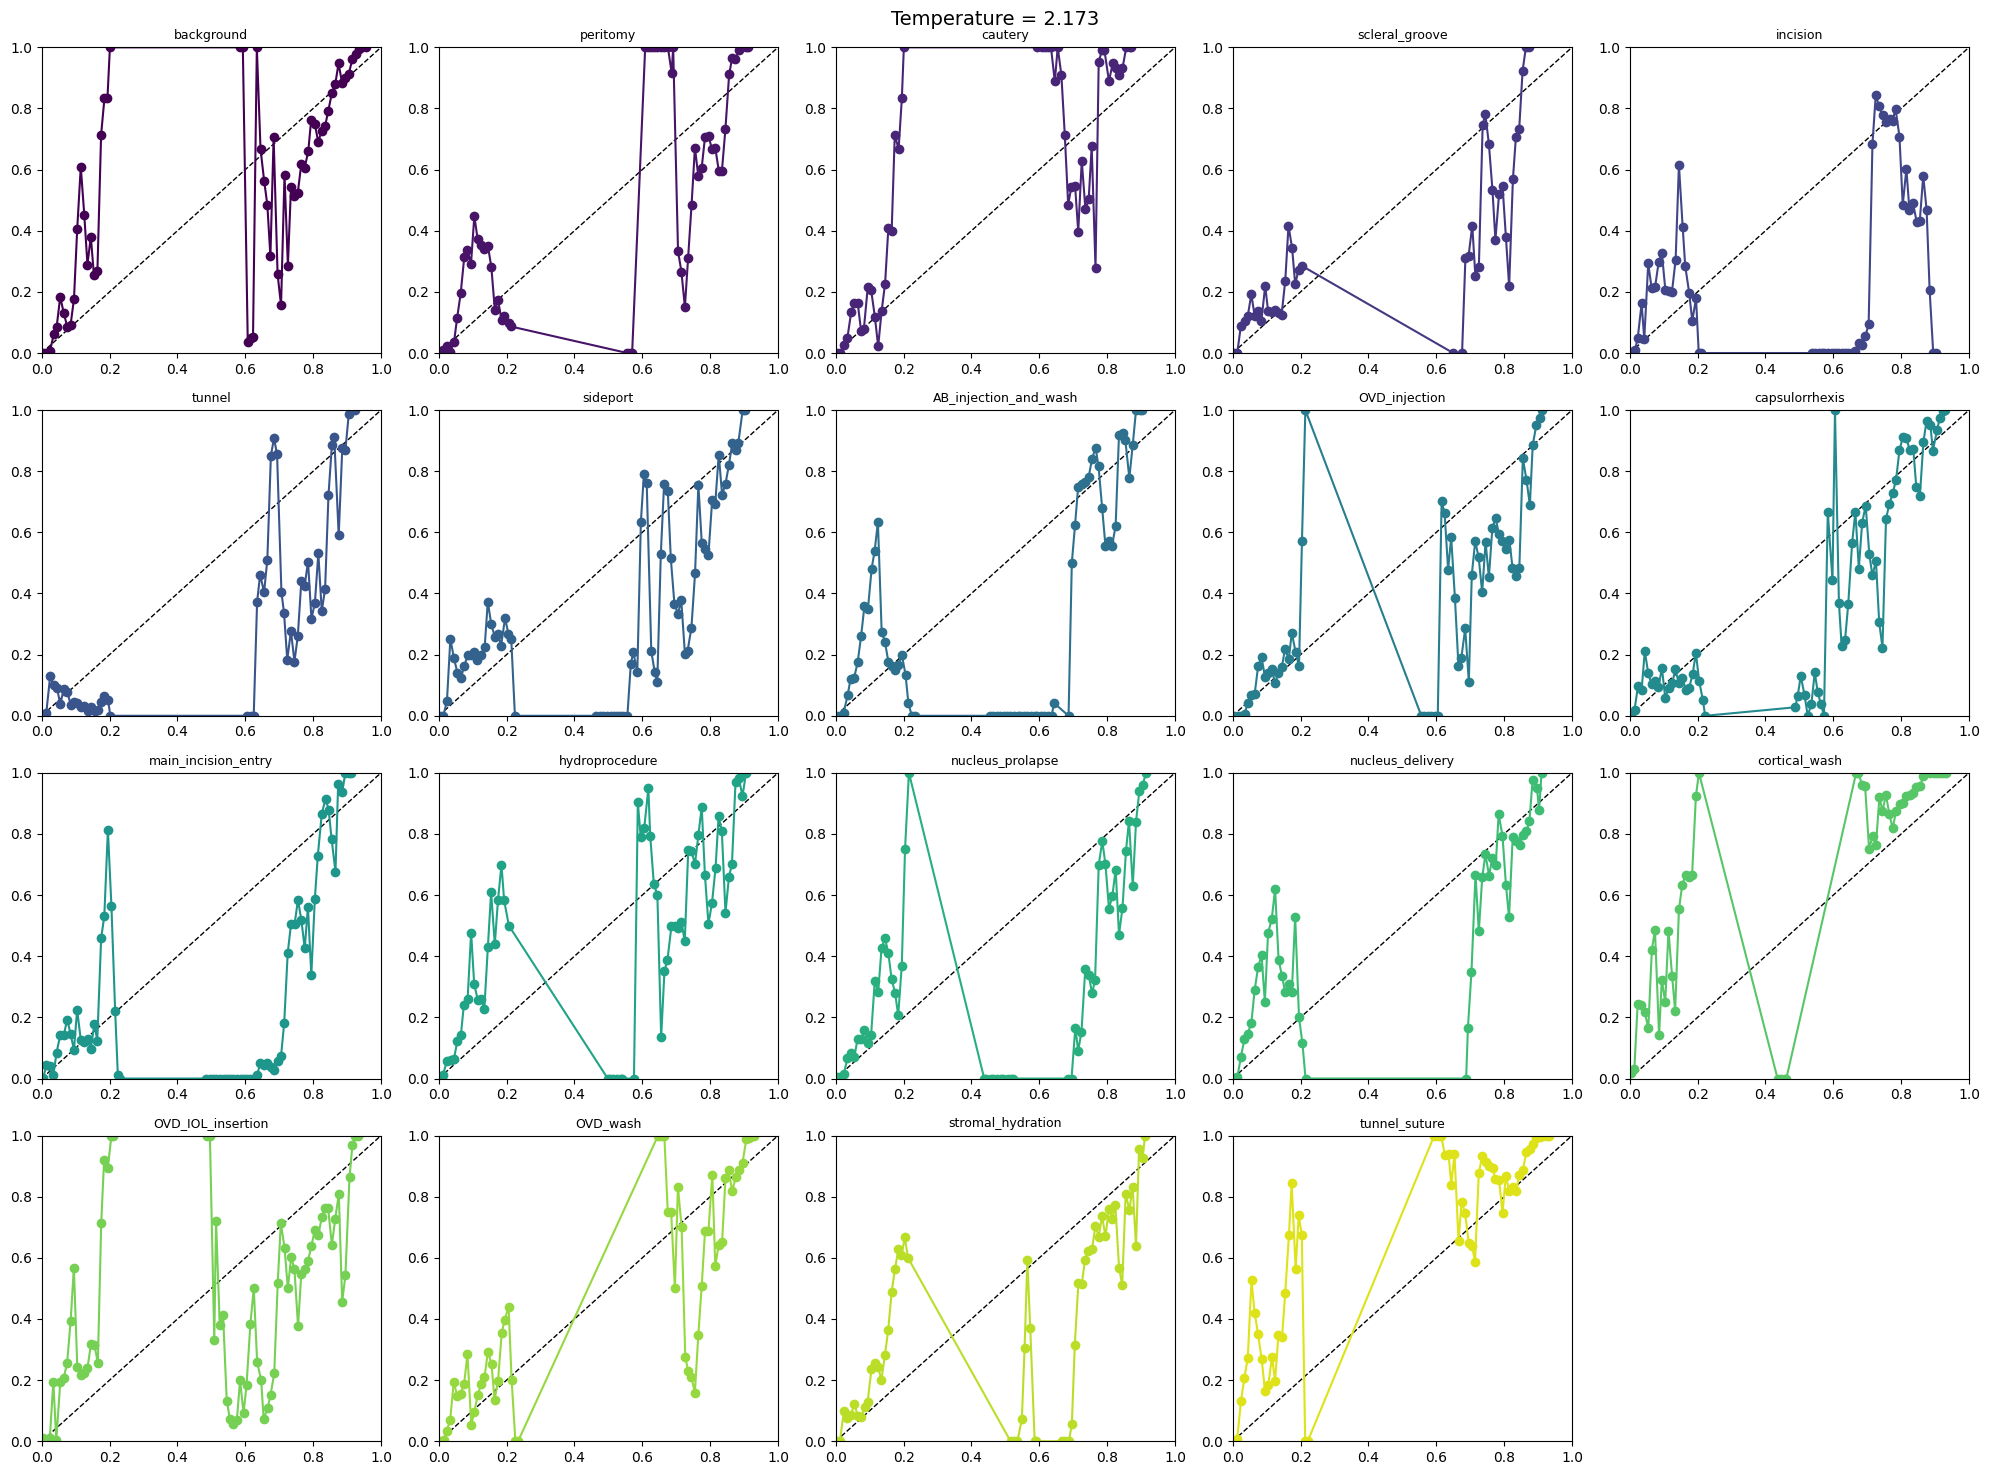

In [78]:
def temperature_scale(probs, temperature, eps=1e-12):
    """Rescale a (N, C) probability array by a temperature T: softmax(log(p) / T)."""
    logp = np.log(probs + eps) / temperature
    logp -= logp.max(axis=1, keepdims=True)
    exp = np.exp(logp)
    return exp / exp.sum(axis=1, keepdims=True)

temperature = 2.173  # <-- set manually and re-run, e.g. try the value from conf_decode_params.json
y_prob_scaled = temperature_scale(y_prob, temperature)
plot_calb = plot_calibration_grid(y_true, y_prob_scaled, class_names, title=f"Temperature = {temperature}")
